# CRISP-DM phase 2 : Data Understanding, D2 (Health care: Heart attack possibility)

Responsable : Aziz (maladies cardiaques)

**À surveiller :** Base Cleveland UCI (303 patients). Attendu : `ca = 4` et `thal = 0` sont des codes de valeur manquante ; 1 doublon.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D2'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D2] lignes=303 pos=165 neg=138 | article: lignes=303 pos=165 neg=138 -> OK


('Health care: Heart attack possibility', (303, 14))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type (numérique, binaire, catégorielle), unité.

In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
age,int64,41,29.0,77.0
sex,int64,2,0.0,1.0
cp,int64,4,0.0,3.0
trestbps,int64,49,94.0,200.0
chol,int64,152,126.0,564.0
fbs,int64,2,0.0,1.0
restecg,int64,3,0.0,2.0
thalach,int64,91,71.0,202.0
exang,int64,2,0.0,1.0
oldpeak,float64,40,0.0,6.2


## 2. Variable cible

target
0    138
1    165
Name: count, dtype: int64

 
 target
0    0.455
1    0.545
Name: count, dtype: float64


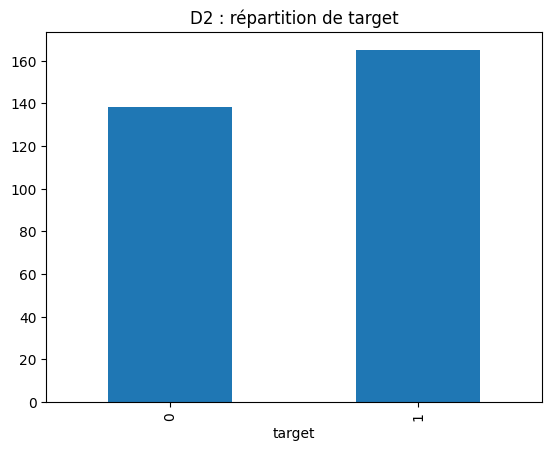

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}'); plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print(df.isna().sum()[df.isna().sum() > 0])
# zéros médicalement impossibles
for c in ['cholesterol', 'chol', 'resting bp s', 'trestbps', 'serum_sodium', 'platelets']:
    if c in df: print(c, '= 0 :', (df[c] == 0).sum())
for c, code in [('ca', 4), ('thal', 0)]:
    if c in df: print(c, '=', code, ':', (df[c] == code).sum())

Series([], dtype: int64)
chol = 0 : 0
trestbps = 0 : 0
ca = 4 : 5
thal = 0 : 2


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes -> {len(df) - n_dup} lignes uniques')
df.drop_duplicates()[target].value_counts()

1 doublons sur 303 lignes -> 302 lignes uniques


target
1    164
0    138
Name: count, dtype: int64

## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.37,9.08,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.97,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.62,17.54,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.26,51.83,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.65,22.91,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


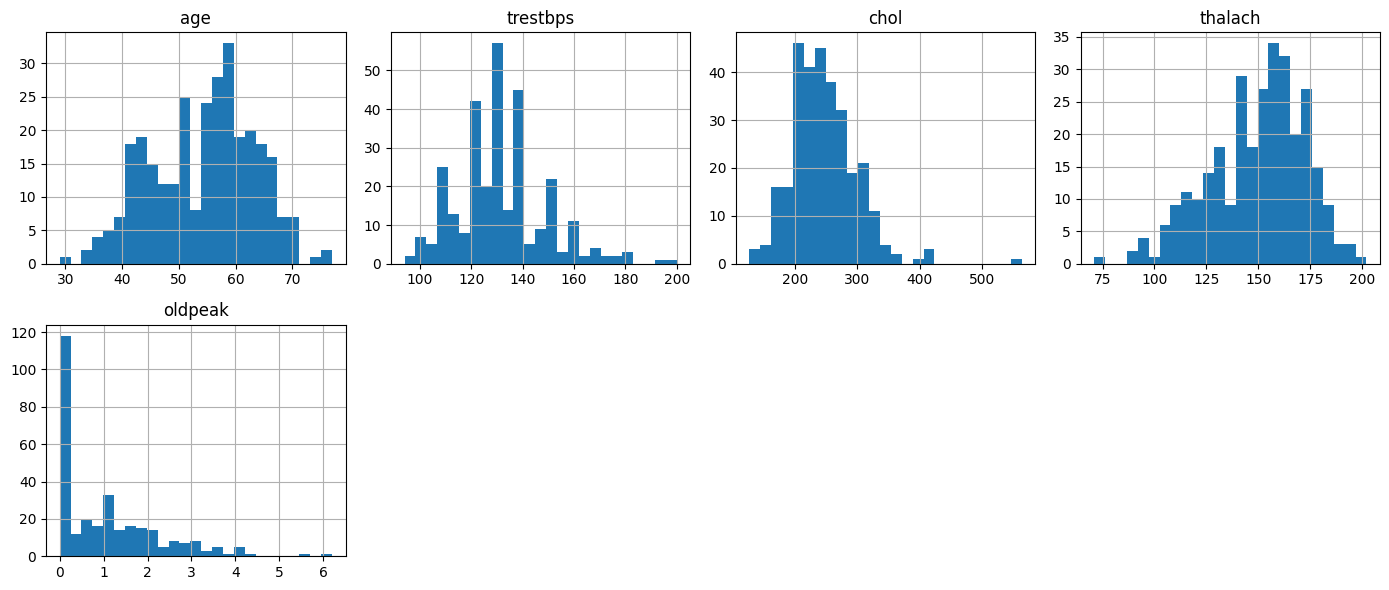

In [8]:
num = [c for c in df.columns if c != target and df[c].nunique() > 5]
df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4)); plt.tight_layout(); plt.show()

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)

trestbps    9
chol        5
oldpeak     5
thalach     1
age         0
dtype: int64

## 7. Variables selon la classe

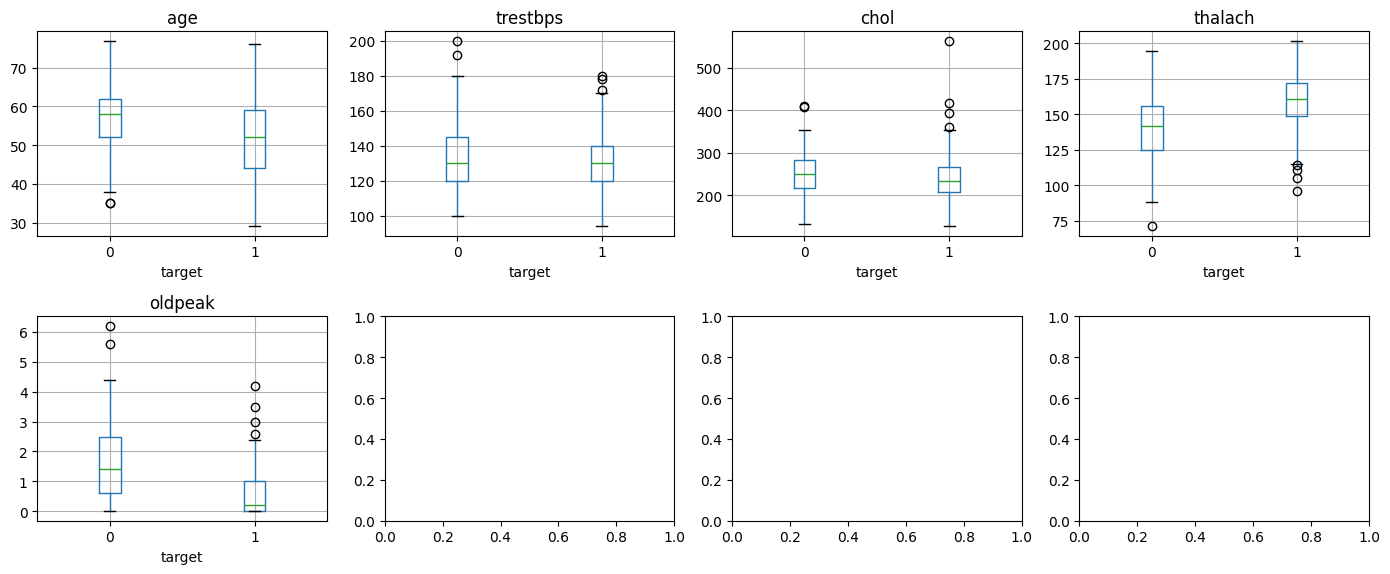

In [10]:
fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
for ax, c in zip(axes.flat, num):
    df.boxplot(column=c, by=target, ax=ax)
plt.suptitle(''); plt.tight_layout(); plt.show()

In [11]:
cat = [c for c in df.columns if c != target and df[c].nunique() <= 5]
for c in cat:
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

target     0     1
sex               
0       0.25  0.75
1       0.55  0.45 

target     0     1
cp                
0       0.73  0.27
1       0.18  0.82
2       0.21  0.79
3       0.30  0.70 

target     0     1
fbs               
0       0.45  0.55
1       0.49  0.51 

target      0     1
restecg            
0        0.54  0.46
1        0.37  0.63
2        0.75  0.25 

target     0     1
exang             
0       0.30  0.70
1       0.77  0.23 

target     0     1
slope             
0       0.57  0.43
1       0.65  0.35
2       0.25  0.75 

target     0     1
ca                
0       0.26  0.74
1       0.68  0.32
2       0.82  0.18
3       0.85  0.15
4       0.20  0.80 

target     0     1
thal              
0       0.50  0.50
1       0.67  0.33
2       0.22  0.78
3       0.76  0.24 



## 8. Corrélations

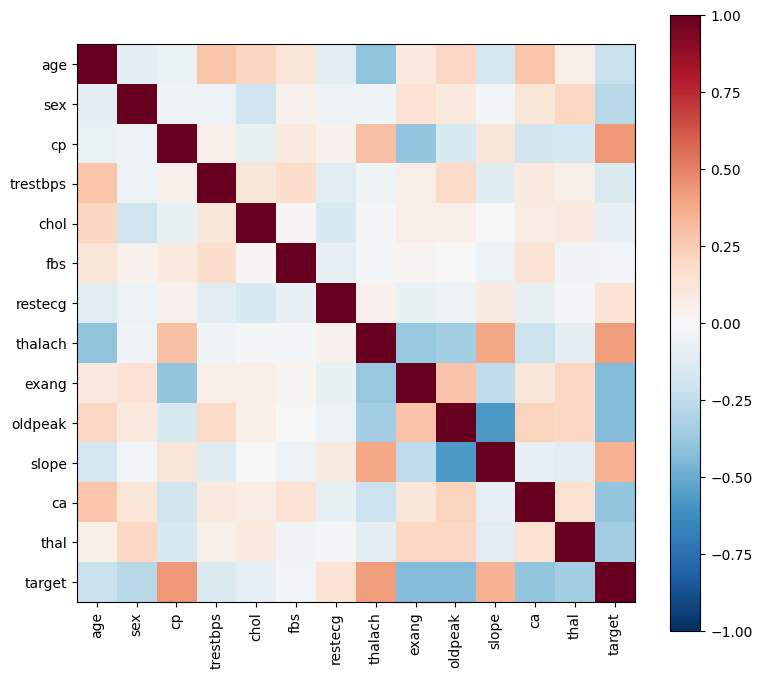

exang      -0.436757
cp          0.433798
oldpeak    -0.430696
thalach     0.421741
ca         -0.391724
slope       0.345877
thal       -0.344029
sex        -0.280937
age        -0.225439
trestbps   -0.144931
restecg     0.137230
chol       -0.085239
fbs        -0.028046
Name: target, dtype: float64

In [12]:
corr = df.select_dtypes('number').corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
plt.colorbar(im); plt.show()
corr[target].drop(target).sort_values(key=abs, ascending=False)

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder :
- Valeurs manquantes / codées à traiter :
- Doublons : gardés (reproduction) + expérience `--dedup`
- Normalisation : StandardScaler dans le Pipeline (ajusté sur le train)
- Points pour la discussion critique :